# PS2 · Quantum Random Number Generator
A qubit in $|+\rangle = H|0\rangle$ yields 0 or 1 with probability exactly 1/2 by the Born rule. We generate **1,000,000** bits, run **10 statistical tests** (our own NIST SP 800-22 implementation), compare against classical PRNGs, and demonstrate **bias mitigation**.

> **Honesty:** Aer is a classical simulator. Its measurement outcomes come from a classical PRNG, so **SIM** bits are pseudo-random under the hood. Only **HW** bits are physically random. Passing statistical tests never *proves* randomness. It means no structure was found.

In [1]:
import sys, json, math, warnings
sys.path.insert(0, '..')
warnings.filterwarnings('ignore')
import numpy as np, matplotlib.pyplot as plt
from IPython.display import display, Markdown
%matplotlib inline
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': 0.25})
def sweep(name): return json.load(open(f'../data/sweeps/{name}.json'))
from qrelay import qrng, stats, extract, plots, hardware

## 1. Circuits: the textbook 1-qubit QRNG, and an 8-qubit parallel version (8 bits per shot)

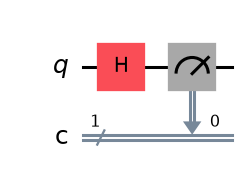

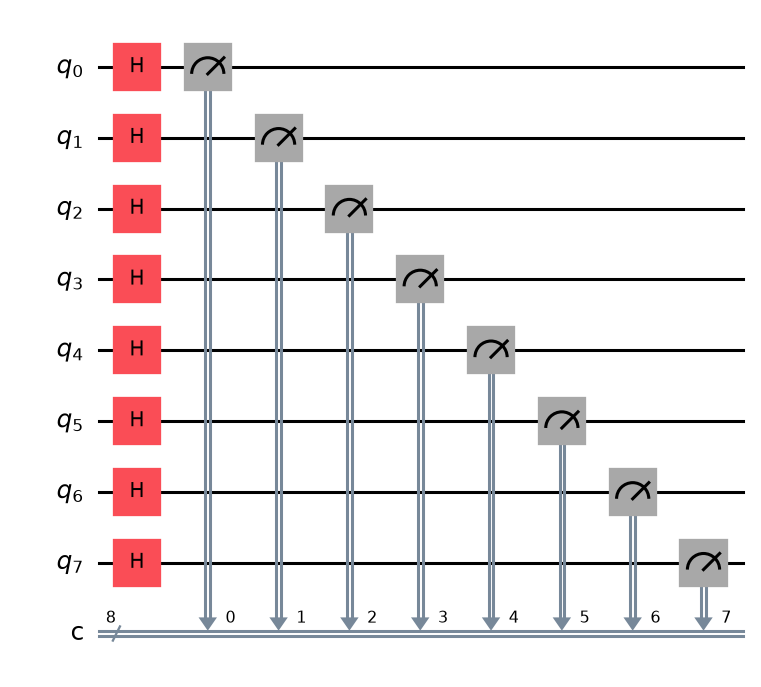

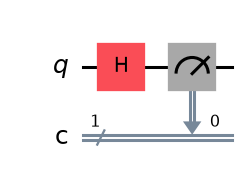

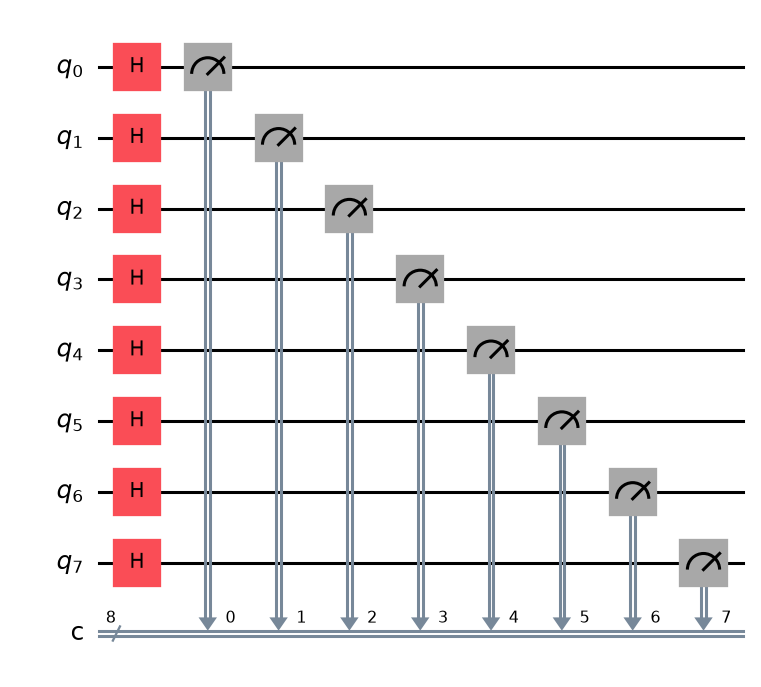

In [2]:
display(qrng.qrng_circuit(1).draw('mpl')); qrng.qrng_circuit(8).draw('mpl')

**Bit ordering:** Qiskit is little-endian (the right-most character of a result string is clbit 0). `qrng.memory_to_bits` reverses each shot so the output order is q0, q1, …

In [3]:
import time
t = time.time(); bits = qrng.generate_bits(1_000_000, m=16, seed=2026)
print(f"{len(bits):,} bits in {time.time()-t:.1f}s   first 64: {''.join(map(str, bits[:64]))}")
print('P(1) =', bits.mean())

1,000,000 bits in 2.9s   first 64: 1001110101010110111111110010001011111101010101010010111000110010
P(1) = 0.499306


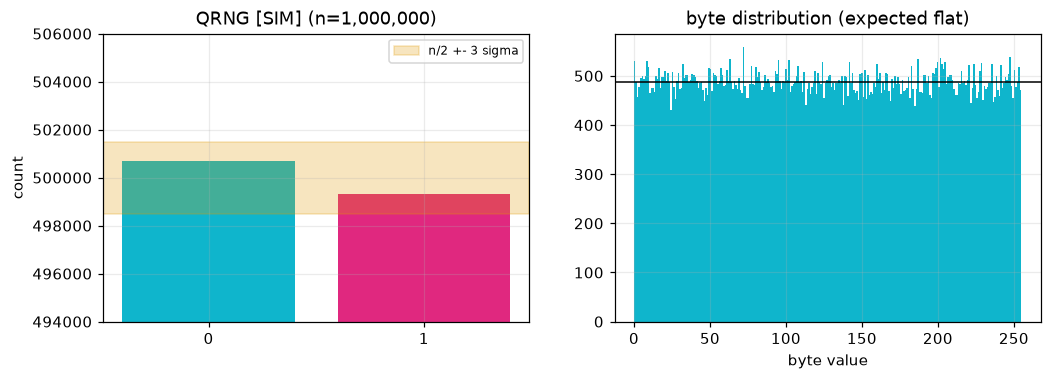

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
plots.bit_histogram(bits, 'QRNG [SIM]', ax=ax[0])
by = np.packbits(bits); ax[1].hist(by, bins=256, color=plots.CYAN); ax[1].axhline(len(by)/256, color='k', lw=1)
ax[1].set(title='byte distribution (expected flat)', xlabel='byte value'); plt.show()

## 2. Statistical test suite: QRNG vs PCG64 vs Mersenne Twister vs RANDU (a deliberately weak LCG)
RANDU is the control: it proves the tests *can* fail. Green = p ≥ 0.01 (pass), red = fail.

In [5]:
N = 1_000_000
sources = {'QRNG [SIM]': bits, 'PCG64': stats.prng_pcg64(N), 'MT19937': stats.prng_mt19937(N), 'RANDU (low byte)': stats.prng_randu(N)}
emu = hardware.latest('HW') or hardware.latest('EMU')
if emu is not None:
    sources[f"QRNG [{emu['source']}] {emu['backend']}"] = hardware.load_bits(emu)
suites = {k: stats.run_suite(v) for k, v in sources.items()}
plots.style_stats(plots.stats_table(suites))

,QRNG [SIM],PCG64,MT19937,RANDU (low byte),QRNG [EMU] fake_brisbane
Frequency (monobit),0.1651,0.5339,0.4952,0.9952,0.9056
Block frequency,0.8618,0.7508,0.8432,1.0000,0.7239
Runs,0.0145,0.8334,0.5535,0.9968,0.9881
Longest run of ones,0.9656,0.5528,0.6584,0.0000,0.8714
Serial (2/3-bit patterns),0.0776,0.9269,0.0259,0.0000,0.2129
Approximate entropy,0.6948,0.6554,0.7423,0.0000,0.8775
Cumulative sums,0.0537,0.1415,0.3932,1.0000,0.8404
Spectral (DFT),0.9488,0.0303,0.5387,0.0000,0.2866
Autocorrelation (lags 1-32),0.1827,1.0000,0.2246,0.0000,1.0000
Byte chi-square,0.6734,0.6280,0.7276,0.0000,0.2150


## 3. Visual tests: bit fingerprints (structure = non-randomness), random walk, autocorrelation

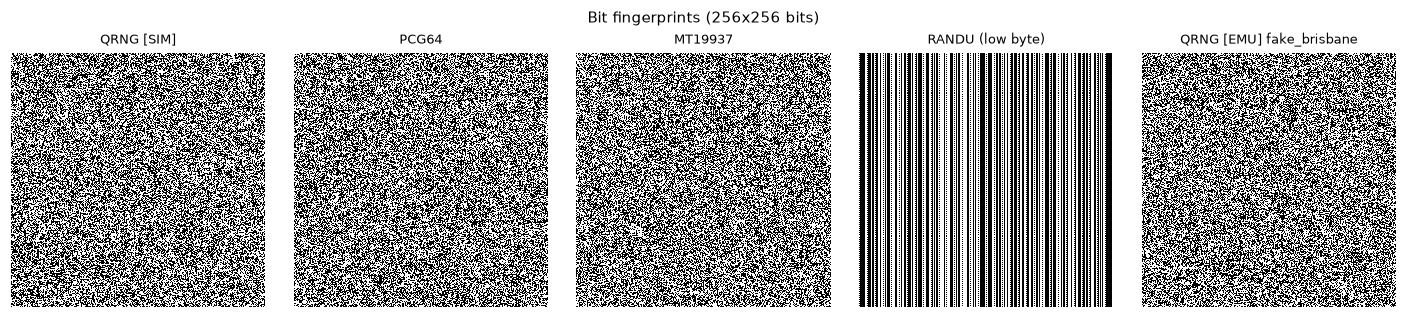

In [6]:
plots.fingerprints(sources); plt.show()

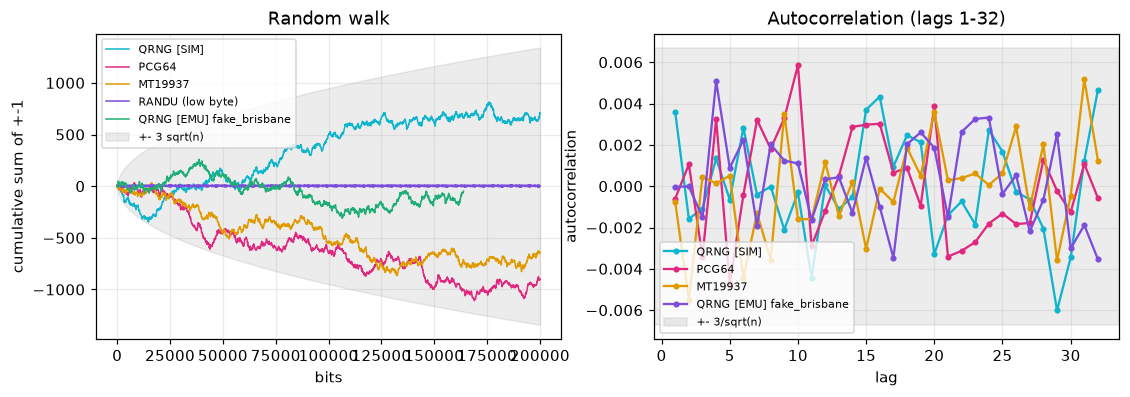

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
plots.random_walk({k: v[:200_000] for k, v in sources.items()}, ax=ax[0])
plots.autocorr({k: stats.autocorrelation_profile(v[:200_000]) for k, v in sources.items() if 'RANDU' not in k}, 200_000, ax=ax[1]); plt.show()

## 4. Bias mitigation
A biased but physically motivated source: an **asymmetric readout error** $P(\text{read }0\mid 1)=0.2$ turns the ideal 50/50 into $P(1)=0.4$.

| extractor | idea | output | yield |
|---|---|---|---|
| Von Neumann | pairs 01→0, 10→1, drop 00/11 | exactly unbiased for i.i.d. bits | p(1−p) per bit |
| XOR pairs | $b_{2i}\oplus b_{2i+1}$ | bias ε → 2ε² | 1/2 |
| Toeplitz hashing | random binary Toeplitz matrix (2-universal hash) | ε-close to uniform (leftover hash lemma) | ≈ H∞ − 2 log₂(1/ε) per block |

In [8]:
biased = qrng.generate_bits(400_000, m=16, seed=77, noise_model=qrng.biased_readout_model(0.2))
res = extract.compare_extractors(biased)
import pandas as pd
pd.DataFrame({k: {'P(1)': round(v['p1'], 4), 'bits out': v['n_out'], 'yield': round(v['yield'], 3),
                  'tests passed': f"{stats.run_suite(v['bits'])['passed']}/10"} for k, v in res.items()}).T

,P(1),bits out,yield,tests passed
raw,0.3993,400000,1.0,0/10
von_neumann,0.5011,95774,0.239,10/10
xor,0.4789,200000,0.5,2/10
toeplitz,0.4989,268710,0.672,10/10


**Trade-off:** Von Neumann is simple and exact but wasteful (24% yield here). XOR is cheap but leaves residual bias (0.48 instead of 0.5, so it still fails). Toeplitz hashing extracts close to the source's min-entropy (≈ 67% yield) with a provable bound, at the cost of a seed and matrix multiplication.

## 5. Hardware / emulated bits: per-qubit bias
Real devices have per-qubit readout asymmetry, which is exactly why extraction matters.

[HW] not available
[EMU] fake_brisbane  163,840 bits  P(1)=0.4999  suite 10/10


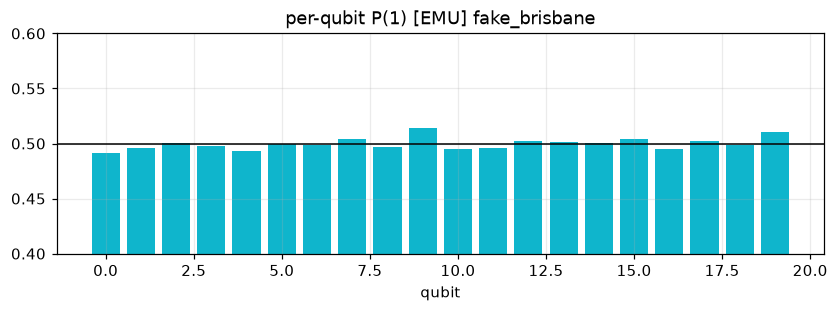

   after Toeplitz: 0.4998 (153,440 bits)


In [9]:
for src in ('HW', 'EMU'):
    rec = hardware.latest(src)
    if rec is None: print(f'[{src}] not available'); continue
    a = hardware.analyze(rec); b = hardware.load_bits(rec)
    print(f"[{src}] {a['backend']}  {len(b):,} bits  P(1)={b.mean():.4f}  suite {a['qrng']['suite']['passed']}/10")
    plt.figure(figsize=(9, 2.6)); plt.bar(range(len(a['qrng']['per_qubit_p1'])), a['qrng']['per_qubit_p1'], color=plots.CYAN)
    plt.axhline(0.5, color='k', lw=1); plt.title(f'per-qubit P(1) [{src}] {a["backend"]}'); plt.xlabel('qubit'); plt.ylim(0.4, 0.6); plt.show()
    ex = extract.compare_extractors(b)
    print('   after Toeplitz:', round(ex['toeplitz']['p1'], 4), f"({ex['toeplitz']['n_out']:,} bits)")

## Conclusions
* 1M simulated QRNG bits pass all 10 tests, as PCG64 and MT do. RANDU fails 6/10 and its fingerprint shows stripes, so the suite discriminates.
* Simulated "quantum" bits are only as random as Aer's PRNG. The physically meaningful comparison is with **HW** bits (section 5).
* A 40/60 biased source fails monobit outright. Von Neumann and Toeplitz both restore all 10 tests, with very different yields.